['BII_S9',
 'BIV_S1',
 'BIV_S2',
 'BIV_S3',
 'BIV_S4',
 'BIV_S5',
 'BIV_S6',
 'BIV_S7',
 'BIV_S8',
 'BIV_S9',
 'BIV_S10',
 'BIV_S31',
 'BIV_S32',
 'BIV_S33',
 'BIV_S34',
 'BIV_S35',
 'BIV_S36',
 'BIV_S37',
 'BIV_S38',
 'BIV_S39',
 'BIV_S40']

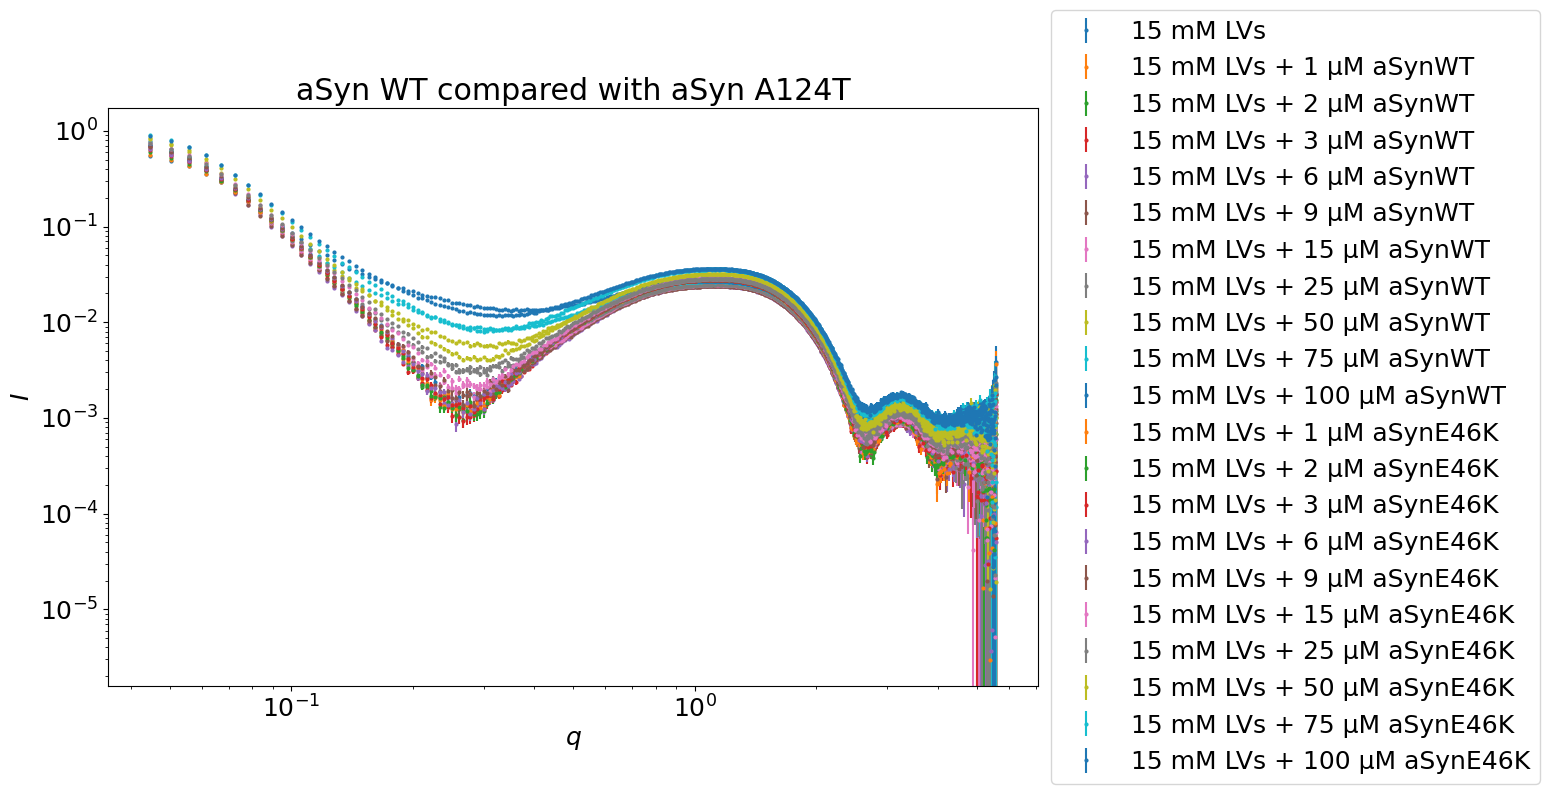

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import fit_lib as fit
import BM29_lib as BM29
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams["text.usetex"] = False
from scipy import optimize
from scipy.optimize import curve_fit

lst_LV4_pure = [
    "BII_S9",
]

lst_aSyn_WT = [
    "BIV_S1",
    "BIV_S2",
    "BIV_S3",
    "BIV_S4",
    "BIV_S5",
    "BIV_S6",
    "BIV_S7",
    "BIV_S8",
    "BIV_S9",
    "BIV_S10",
]

lst_aSyn_A124T = [
    # "BIV_S21",
    # "BIV_S22",
    # "BIV_S23",
    # "BIV_S24",
    # "BIV_S25",
    # "BIV_S26",
    "BIV_S27",
    "BIV_S28",
    "BIV_S29",
    "BIV_S30",
]

lst_aSyn_E61V = [
    "BIV_S11",
    "BIV_S12",
    "BIV_S13",
    "BIV_S14",
    "BIV_S15",
    "BIV_S16",
    "BIV_S17",
    "BIV_S18",
    "BIV_S19",
    "BIV_S20",
]

lst_aSyn_E46K = [
    "BIV_S31",
    "BIV_S32",
    "BIV_S33",
    "BIV_S34",
    "BIV_S35",
    "BIV_S36",
    "BIV_S37",
    "BIV_S38",
    "BIV_S39",
    "BIV_S40",
]

title = "aSyn WT compared with aSyn A124T"
who = lst_LV4_pure + lst_aSyn_WT +  lst_aSyn_E46K
BM29.plot_together(who, title)
who

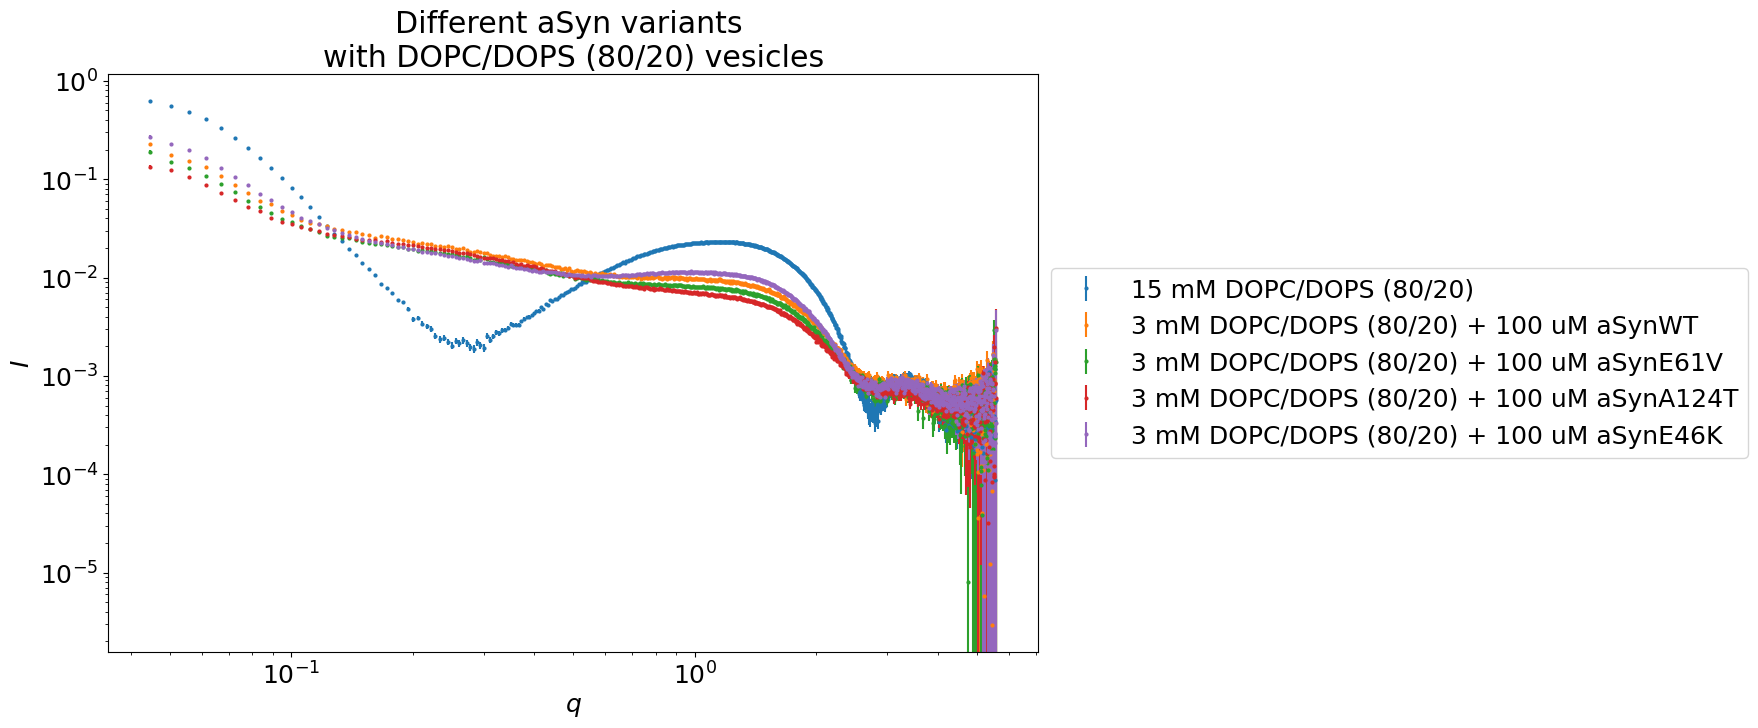

In [2]:
title = "Different aSyn variants \nwith DOPC/DOPS (80/20) vesicles"
lst_variants_DOPC_GM1 = [
    "BIX_S2",
    "BVI_S4",
    "BVI_S8",
    "BVI_S9",
    "BVI_S10",
]

lst_variants_POPG = [
    "BIX_S1",
    "BVI_S14",
    "BVI_S18",
    "BVI_S19",
    "BVI_S20",
]

lst_variants_DOPS = [
    "BII_S10",
    "BVII_S1",
    "BVII_S2",
    # "BVII_S3",
    "BVII_S8",
    # "BVII_S9",
    "BVII_S13",
    # "BVII_S14",
    "BVII_S18",
    # "BVII_S19",
]
lst_variants_DOPC_DOPS = [
    "BII_S11",
    # # "BVII_S4",
    # "BVII_S5",
    "BVII_S6",
    # "BVII_S10",
    "BVII_S11",
    # "BVII_S15",
    "BVII_S16",
    # "BVII_S20",
    "BVII_S21",
]

who = lst_variants_DOPC_DOPS
BM29.plot_together(who, title)

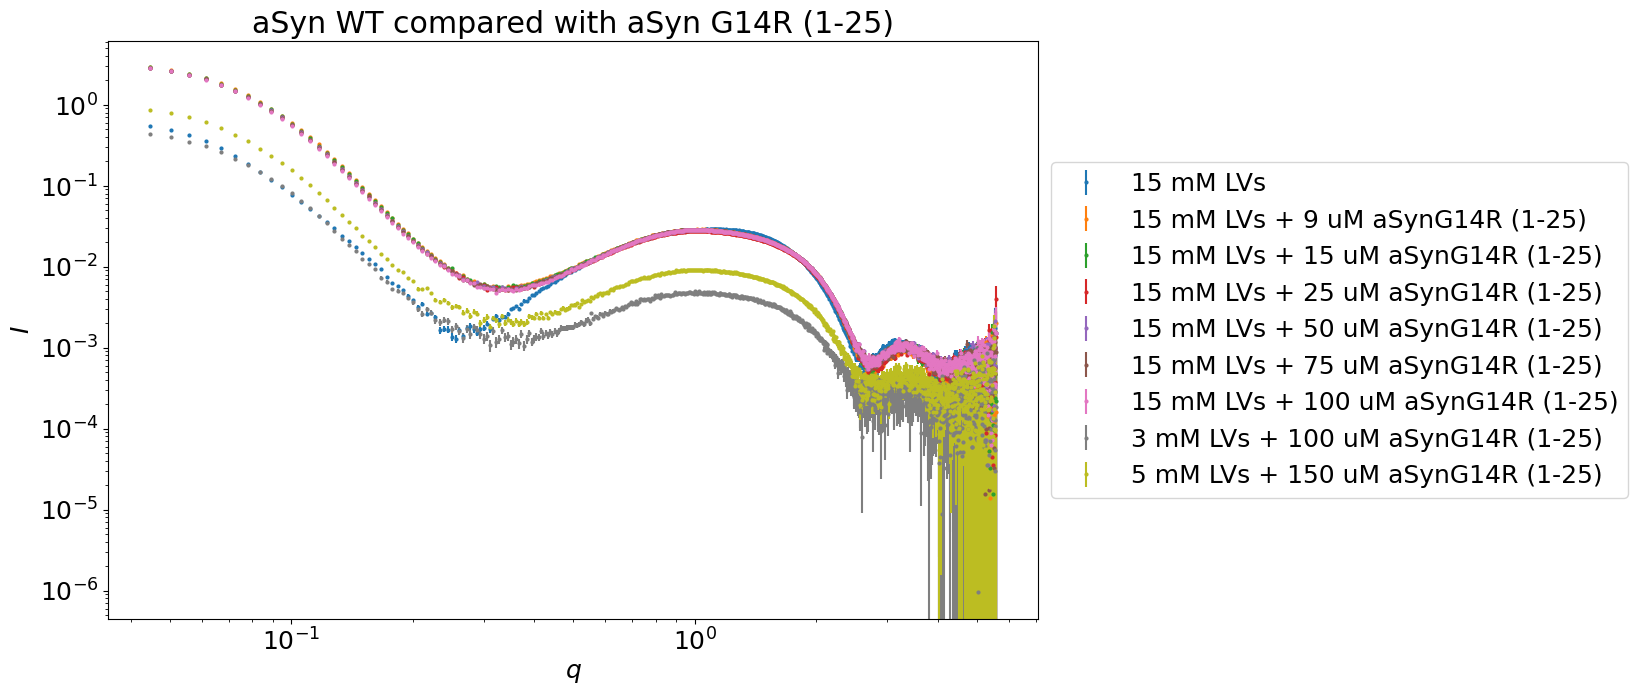

In [3]:
title = "aSyn WT compared with aSyn G14R (1-25)"
lst_aSyn_WT = [
    # "BIV_S1",
    # "BIV_S2",
    # "BIV_S3",
    # "BIV_S4",
    "BIV_S5",
    "BIV_S6",
    "BIV_S7",
    "BIV_S8",
    "BIV_S9",
    "BIV_S10",
]

lst_aSyn_G14R = [
    # "BIX_S3",
    # "BIX_S4",
    # "BIX_S5",
    # "BIX_S6",
    "BIX_S7",
    "BIX_S8",
    "BIX_S9",
    "BVIII_S15",
    "BVIII_S16",
    "BVIII_S17",
    "BVIII_S18",
    "BVIII_S19",
]

who = lst_LV4_pure + lst_aSyn_G14R # + lst_aSyn_WT 
BM29.plot_together(who, title)

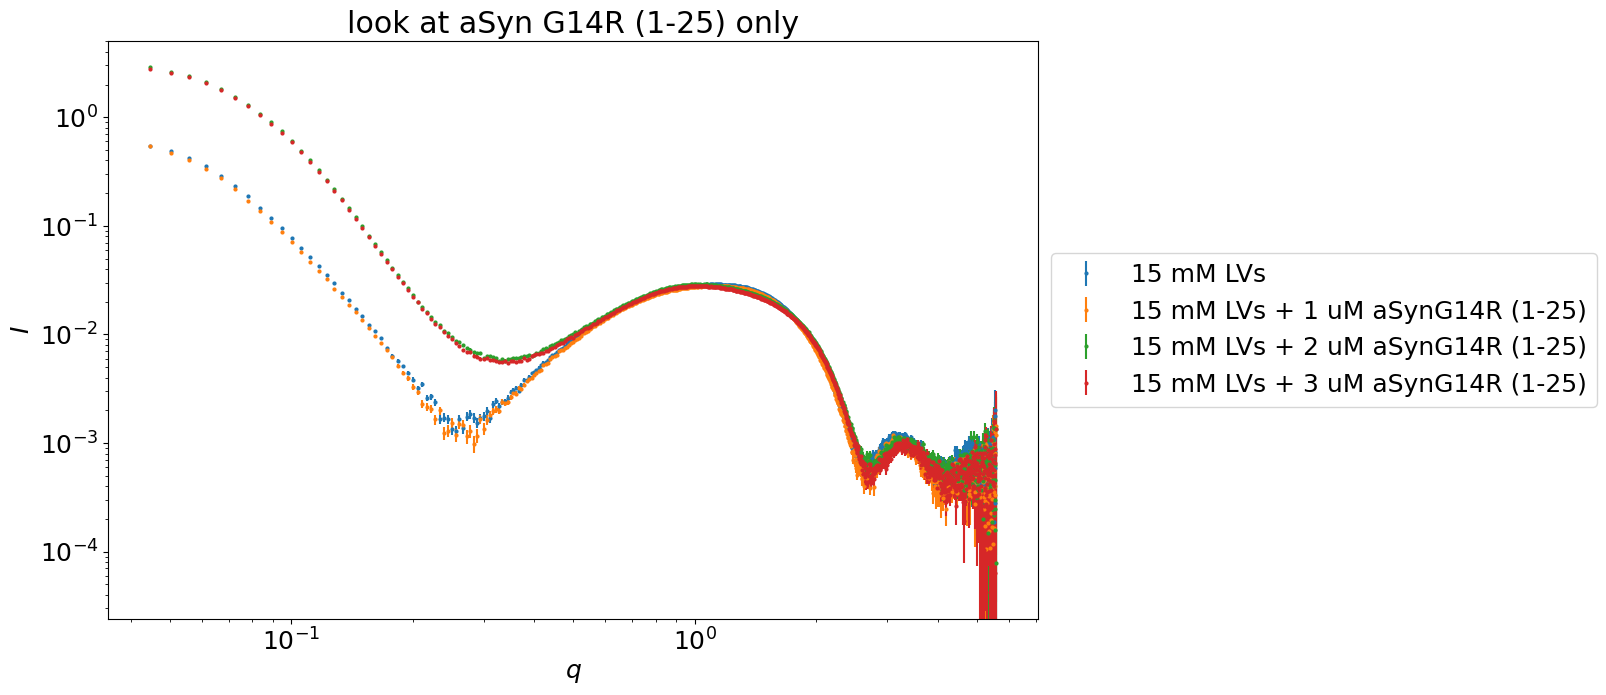

In [4]:
title = "look at aSyn G14R (1-25) only"
lst_aSyn_G14R = [
    "BIX_S3",
    "BIX_S4",
    "BIX_S5",

    # "BVIII_S11",
    # "BVIII_S12",
    # "BVIII_S13",
    # "BVIII_S14",

    # "BIX_S6",
    # "BIX_S7",
    # "BIX_S8",
    # "BIX_S9",
]

who = lst_LV4_pure + lst_aSyn_G14R
BM29.plot_together(who, title)

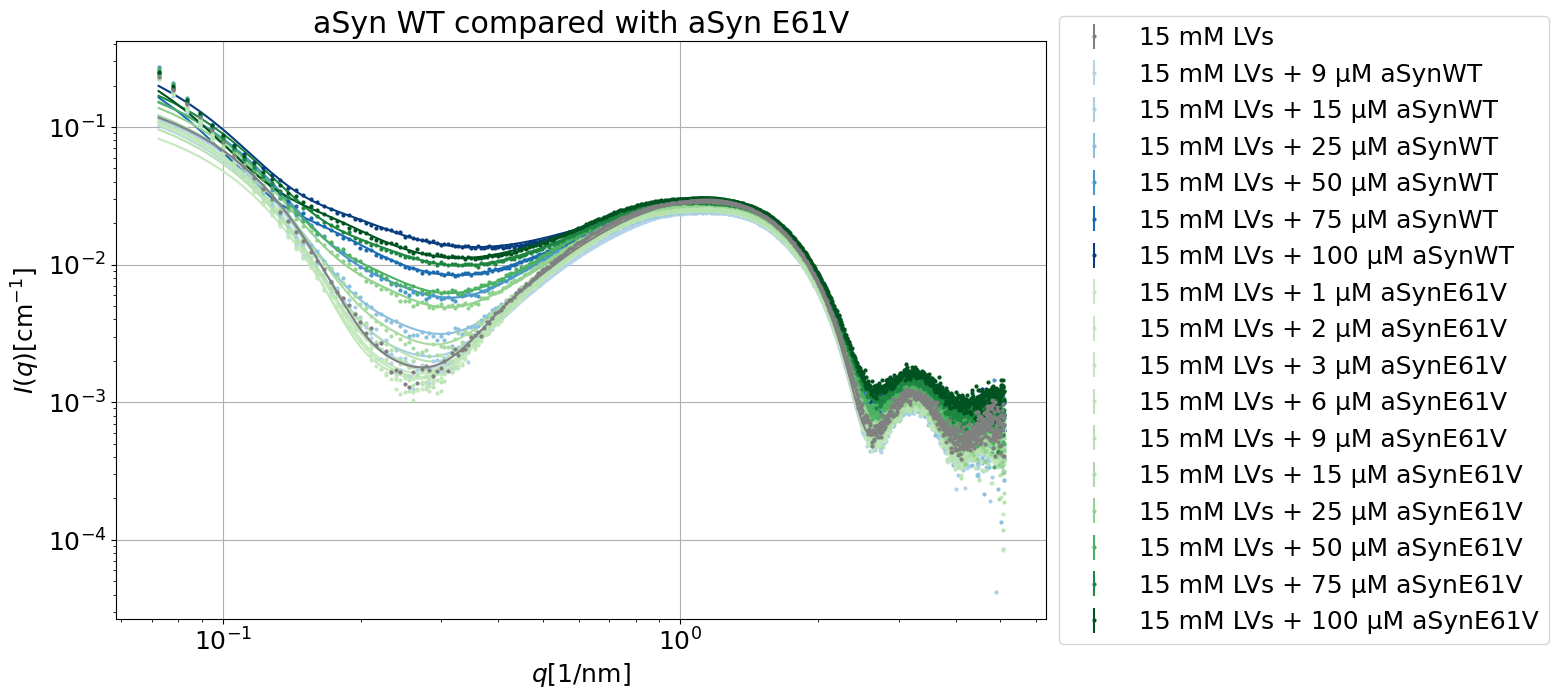

In [5]:
# Show curves WT vs A124T version 1
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colormaps


def plot_together(who, title):
    """
    who: list of samples of the form "BII_S3"
    """

    plt.close("all")

    f = plt.figure(figsize=(12, 7.5))

    # Concentration range for color scaling
    c_min = 1.0
    c_max = 100.0

    # Blue and red colormaps
    blues = colormaps["Blues"]
    reds = colormaps["Reds"]
    oranges = colormaps["Oranges"]
    greens = colormaps["Greens"]

    for sample in who:

        block = sample.split("_")[0]
        block_path = BM29.blockpath(block)
        dir_names = [x.name for x in block_path.iterdir()]

        for dir_name in dir_names:

            if dir_name[:-13].endswith(sample):

                sub_dat_path = (
                    block_path
                    / dir_name
                    / "avg_and_sub"
                    / BM29.sample_dict[sample]
                )

                q, I, Ierr = np.loadtxt(sub_dat_path, unpack=True)
                mask = (q >= 0.07) & (q <= 5.1)
                q    = q[mask]
                I    = I[mask]
                Ierr = Ierr[mask]

                # -------------------------
                # Choose color
                # -------------------------
                concentration = BM29.concentrations[sample]

                # Normalize concentration to 0...1
                norm = (concentration - c_min) / (c_max - c_min)

                # Avoid extremely pale colors
                norm = 0.25 + 0.70 * norm

                if sample in lst_LV4_pure:
                    color = "grey"
                elif sample in lst_aSyn_WT:
                    color = blues(norm)
                elif sample in lst_aSyn_A124T:
                    color = reds(norm)
                elif sample in lst_aSyn_E46K:
                    color = oranges(norm)
                elif sample in lst_aSyn_E61V:
                    color = greens(norm)
                else:
                    color = "black"
                fit_function_name = "ULV_spheric_asym_C4"
                fit_function = lambda q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale, c4: fit.ULV_spheric_asym(q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,      0, 0, c4)
                if sample in lst_LV4_pure:
                    plt.errorbar(q,I, np.zeros(len(I)),ls="None",marker="o",color=color,label=BM29.nice_sample_names[sample],markersize=2.0, zorder=10)
                    plt.plot(q, fit_function(q, *BM29.best_fits[sample][fit_function_name][1]), color=color, zorder=10)
                else:
                    plt.errorbar(q,I,np.zeros(len(I)),ls="None",marker="o",color=color,label=BM29.nice_sample_names[sample],markersize=2.0)
                    plt.plot(q, fit_function(q, *BM29.best_fits[sample][fit_function_name][1]), color=color)

    plt.xscale("log")
    plt.yscale("log")
    plt.title(title)
    plt.xlabel('$q [1/\\mathrm{nm}]$')
    plt.ylabel('$I(q) [\\mathrm{cm}^{-1}]$')
    plt.grid()


    legend = plt.legend(
        loc="center left",
        bbox_to_anchor=(1, 0.5),
        alignment="left"
    )

    return f

who = lst_LV4_pure + lst_aSyn_WT + lst_aSyn_E61V

f = plot_together(
    who,
    "aSyn WT compared with aSyn E61V"
)
target_folder = Path("C:/Users/riko05/Documents/8. SoSe 26/Code/BM29_data_and_analysis_2026/analysis_BM29_July2026/Results_and_Figures/Aug27/Plot_WT_A124T")
# f.savefig(target_folder / "all_curves.png", dpi=600, bbox_inches="tight")

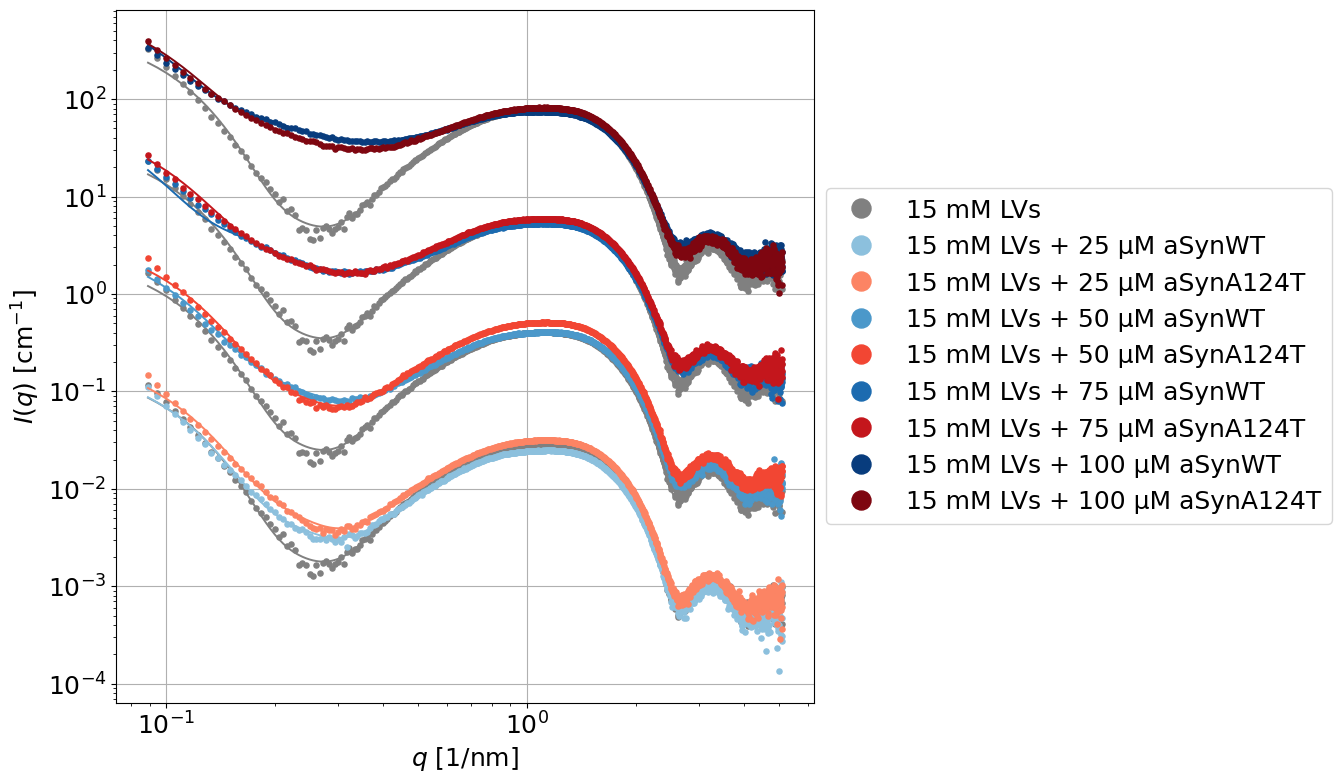

In [6]:
# Show curves WT vs A124T
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colormaps
marker_standard = 3.7
lw_standard = 1.4
fit_color = "whitesmoke"


def plot_together(who, title):

    plt.close("all")

    f = plt.figure(figsize=(9, 9))

    # =========================================================
    # Concentrations
    # =========================================================

    concentrations = {
        "BII_S9": 0.0,

        "BIV_S1": 1.0,
        "BIV_S2": 2.0,
        "BIV_S3": 3.0,
        "BIV_S4": 6.0,
        "BIV_S5": 9.0,
        "BIV_S6": 15.0,
        "BIV_S7": 25,
        "BIV_S8": 50,
        "BIV_S9": 75,
        "BIV_S10": 100,

        "BIV_S21": 1.0,
        "BIV_S22": 2.0,
        "BIV_S23": 3.0,
        "BIV_S24": 6.0,
        "BIV_S25": 9.0,
        "BIV_S26": 15.0,
        "BIV_S27": 25,
        "BIV_S28": 50,
        "BIV_S29": 75,
        "BIV_S30": 100,

        
    }

    # =========================================================
    # Vertical shifts
    #
    # All three curves belonging to one concentration
    # receive exactly the same shift.
    # =========================================================

    shift_factors = {
        # 1.0:    1,
        # 2.0:    3,
        # 3.0:    9,
        # 6.0:    27,
        # 9.0:    81,
        # 15.0:   243,
        25.0:   1,
        50.0:   14**(1),
        75.0:   14**(2),
        100.0:  14**(3),
    }

    # =========================================================
    # Color scaling
    # =========================================================

    c_min = 1.0
    c_max = 100.0

    blues = colormaps["Blues"]
    reds = colormaps["Reds"]

    # =========================================================
    # Helper function: load sample
    # =========================================================

    def load_sample(sample):

        block = sample.split("_")[0]
        block_path = BM29.blockpath(block)

        for dir_name in block_path.iterdir():

            if dir_name.name[:-13].endswith(sample):

                sub_dat_path = (
                    dir_name
                    / "avg_and_sub"
                    / BM29.sample_dict[sample]
                )

                q, I, Ierr = np.loadtxt(
                    sub_dat_path,
                    unpack=True
                )

                mask = (q >= 0.085) & (q <= 5.1)

                return (
                    q[mask],
                    I[mask],
                    Ierr[mask]
                )

        raise FileNotFoundError(
            f"Could not find data for {sample}"
        )

    # =========================================================
    # Fit function
    # =========================================================

    fit_function_name = "ULV_spheric_asym_C4"

    def fit_function(
        q,
        R,
        sigma_R,
        rho_h1,
        rho_h2,
        sigma_h1,
        sigma_h2,
        sigma_c,
        z_h,
        scale,
        c4
    ):

        return fit.ULV_spheric_asym(
            q,
            R,
            sigma_R,
            rho_h1,
            rho_h2,
            sigma_h1,
            sigma_h2,
            sigma_c,
            z_h,
            scale,
            0,
            0,
            c4
        )

    # =========================================================
    # Pure LV label should only appear once
    # =========================================================

    lv_label_added = False

    # =========================================================
    # Plot concentration by concentration
    # =========================================================

    concentrations_to_plot = sorted(
        set(
            concentrations[sample]
            for sample in who
        )
    )

    for concentration in concentrations_to_plot:

        # -----------------------------------------------------
        # Find WT sample at this concentration
        # -----------------------------------------------------

        wt_samples = [
            sample for sample in who
            if sample in lst_aSyn_WT
            and concentrations.get(sample) == concentration
        ]

        # -----------------------------------------------------
        # Find A124T sample at this concentration
        # -----------------------------------------------------

        a124t_samples = [
            sample for sample in who
            if sample in lst_aSyn_A124T
            and concentrations.get(sample) == concentration
        ]

        # -----------------------------------------------------
        # Skip concentration if one of the protein samples
        # is missing
        # -----------------------------------------------------

        if not wt_samples or not a124t_samples:
            continue

        wt_sample = wt_samples[0]
        a124t_sample = a124t_samples[0]

        # -----------------------------------------------------
        # Pure LV reference sample
        # -----------------------------------------------------

        if not lst_LV4_pure:
            continue

        lv_sample = lst_LV4_pure[0]

        # -----------------------------------------------------
        # Vertical shift
        #
        # This SAME factor is applied to:
        #   WT
        #   A124T
        #   pure LV
        # -----------------------------------------------------

        shift = shift_factors[concentration]

        # =====================================================
        # COLORS
        # =====================================================

        norm = (
            concentration - c_min
        ) / (
            c_max - c_min
        )

        # Avoid extremely pale colors
        norm = 0.25 + 0.70 * norm

        wt_color = blues(norm)
        a124t_color = reds(norm)
        lv_color = "grey"

        # =====================================================
        # PURE LV
        # =====================================================

        q, I, Ierr = load_sample(lv_sample)

        I_fit = fit_function(
            q,
            *BM29.best_fits[
                lv_sample
            ][fit_function_name][1]
        )

        # Apply EXACTLY THE SAME shift as WT and A124T
        I_shifted = I * shift
        I_fit_shifted = I_fit * shift

        # -----------------------------------------------------
        # Add pure LV to legend only once
        # -----------------------------------------------------

        if not lv_label_added:

            lv_label = BM29.nice_sample_names[lv_sample]
            lv_label_added = True

        else:

            lv_label = "_nolegend_"

        plt.plot(
            q,
            I_shifted,
            ls="None",
            marker="o",
            color=lv_color,
            markersize=marker_standard,
            label=lv_label
        )

        plt.plot(
            q,
            I_fit_shifted,
            color=lv_color,
            label="_nolegend_",
            lw=lw_standard #, zorder=4
        )

        # =====================================================
        # WT
        # =====================================================

        q, I, Ierr = load_sample(wt_sample)

        I_fit = fit_function(
            q,
            *BM29.best_fits[
                wt_sample
            ][fit_function_name][1]
        )

        # Apply concentration shift
        I_shifted = I * shift
        I_fit_shifted = I_fit * shift

        plt.plot(
            q,
            I_shifted,
            ls="None",
            marker="o",
            color=wt_color,
            markersize=marker_standard,
            label=BM29.nice_sample_names[wt_sample]
        )

        plt.plot(
            q,
            I_fit_shifted,
            color=wt_color,
            label="_nolegend_",
            lw=lw_standard #, zorder=4
        )

        # =====================================================
        # A124T
        # =====================================================

        q, I, Ierr = load_sample(a124t_sample)

        I_fit = fit_function(
            q,
            *BM29.best_fits[
                a124t_sample
            ][fit_function_name][1]
        )

        # Apply SAME concentration shift
        I_shifted = I * shift
        I_fit_shifted = I_fit * shift

        plt.plot(
            q,
            I_shifted,
            ls="None",
            marker="o",
            color=a124t_color,
            markersize=marker_standard,
            label=BM29.nice_sample_names[a124t_sample]
        )

        plt.plot(
            q,
            I_fit_shifted,
            color=a124t_color,
            label="_nolegend_",
            lw=lw_standard #, zorder=4
        )



    # =========================================================
    # Formatting
    # =========================================================

    plt.xscale("log")
    plt.yscale("log")

    # plt.title(title)

    plt.xlabel(r'$q\ [1/\mathrm{nm}]$')
    plt.ylabel(r'$I(q)\ [\mathrm{cm}^{-1}]$')

    plt.grid()

    plt.legend(
        loc="center left",
        bbox_to_anchor=(1, 0.5),
        alignment="left",
        markerscale=3.7
    )

    return f


# =============================================================
# Run
# =============================================================

who = lst_LV4_pure + lst_aSyn_WT + lst_aSyn_A124T

f = plot_together(
    who,
    "aSyn WT compared with aSyn A124T"
)

target_folder = Path(
    "C:/Users/riko05/Documents/8. SoSe 26/Code/"
    "BM29_data_and_analysis_2026/analysis_BM29_July2026/"
    "Results_and_Figures/Aug27/Plot_WT_A124T"
)

# =============================================================
# Save
# =============================================================

f.savefig(
    target_folder / "all_curves_shifted.png",
    dpi=700,
    bbox_inches="tight"
)


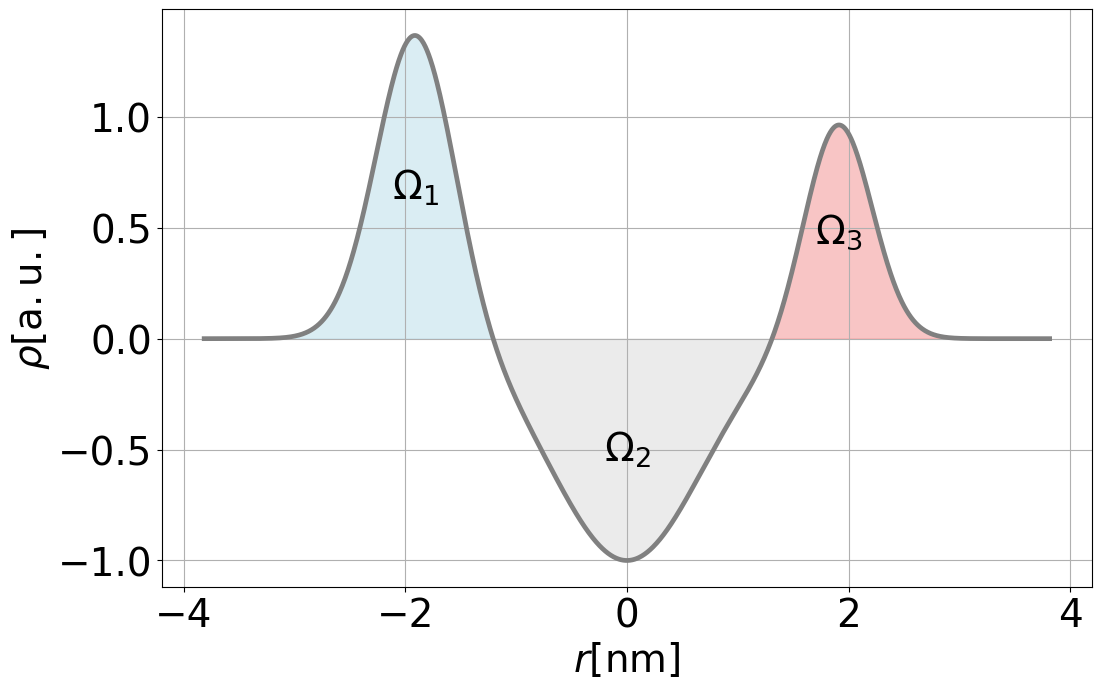

In [7]:
# Make Omega Explanation plot
def gaussian(r, rho_pos, sigma, rho_h):
    return rho_h * np.exp(-0.5 * ((r - rho_pos) / sigma)**2)
def EDP_plot(R, sigma_h1, sigma_h2, sigma_tail, rho_h1, rho_h2, eps_h1, eps_h2, info_text, title, z_h3=2.2, sigma_h3=1, rho_h3=0):

    R = 0
    r = np.linspace(R - 2*eps_h1, R + 2*eps_h2, 1500)

    rho_h   = [rho_h1, -1, rho_h2, rho_h3]
    rho_pos = [R - eps_h1, R, R + eps_h2, R + z_h3]
    sigma   = [sigma_h1, sigma_tail, sigma_h2, sigma_h3]

    # Calculate individual Gaussian components
    gaussians = []
    for i in range(4):
        gaussians.append(gaussian(r, rho_pos[i], sigma[i], rho_h[i]))

    # Total EDP
    rho = np.sum(gaussians, axis=0)
    EDP_int = np.trapezoid(rho, r)

    fig = plt.figure(figsize=(12, 7.5))

    # Colors for Ω₁, Ω₂, Ω₃
    area_colors = ['lightblue', 'lightgrey', 'lightcoral']
    root_indices = []
    for i in range(len(r)):
        if ((rho[i-1]>0 and rho[i]<0) or (rho[i-1]<0 and rho[i]>0)) and (np.abs(r[i]) < eps_h1):
            root_indices.append(i)
    # Boundaries between the three regions
    boundaries = [
        -np.inf,
        r[root_indices[0]],
        r[root_indices[1]],
        np.inf
    ]

    # Shade the actual summed EDP curve in the three regions
    for i in range(3):
        mask = (r >= boundaries[i]) & (r < boundaries[i + 1])

        # Only shade the part between the EDP and zero
        plt.fill_between(
            r[mask],
            0,
            rho[mask],
            color=area_colors[i],
            alpha=0.45
        )

    # Plot total EDP
    plt.plot(
        r,
        rho,
        color='grey',
        linewidth=3.4,
        label='EDP'
    )

    # Ω labels at the centers of the three regions
    labels = [r'$\Omega_1$', r'$\Omega_2$', r'$\Omega_3$']

    for i in range(3):
        mask = (r >= boundaries[i]) & (r < boundaries[i + 1])

        r_region = r[mask]
        rho_region = rho[mask]

        # Position label near the middle of the actual bump
        if i == 0:
            x_label = rho_pos[0]
        elif i == 1:
            x_label = rho_pos[1]
        else:
            x_label = rho_pos[2]

        # Interpolate EDP at label position
        y_label = np.interp(x_label, r, rho)

        plt.text(
            x_label,
            y_label * 0.5,
            labels[i],
            ha='center',
            va='center',
            fontsize=28,
            color='black'
        )

    plt.xlabel(r'$r[\mathrm{nm}]$', fontsize=28)
    plt.ylabel(r'$\rho\mathrm{[a.u.]}$', fontsize=28)
    # plt.title(title)
    plt.grid(True)
    tick_params = {'labelsize': 28}
    plt.tick_params(axis='both', **tick_params)

    # legend = plt.legend()
    # EDP_area = f"EDP_area = {EDP_int:.3g}"
    # legend.set_title(EDP_area)

    return fig

fig = EDP_plot(16.09, 0.3527, 0.3049, 0.6648, 1.383, 0.9795, 1.907, 1.907, "", "", z_h3=2.2, sigma_h3=1, rho_h3=0)

# fig.savefig(
#     target_folder / "Omega_explanation.png",
#     dpi=500,
#     bbox_inches="tight"
# )


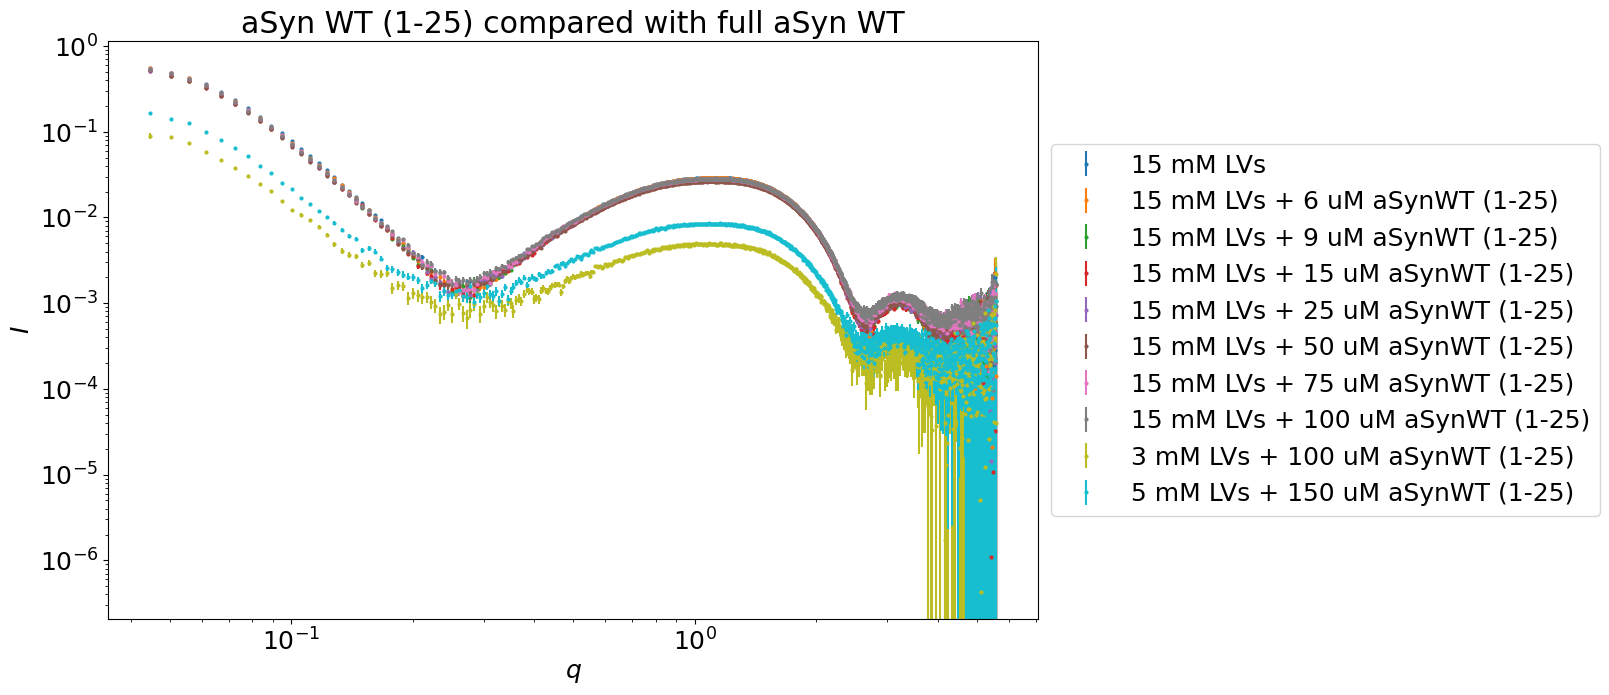

In [8]:
title = "aSyn WT (1-25) compared with full aSyn WT"
lst_aSyn_WT = [
    "BIV_S1",
    "BIV_S2",
    "BIV_S3",
    "BIV_S4",
    "BIV_S5",
    "BIV_S6",
    "BIV_S7",
    "BIV_S8",
    "BIV_S9",
    "BIV_S10",
]

lst_aSyn_WT_1_25 = [
    "BVIII_S1",
    "BVIII_S2",
    "BVIII_S3",
    "BVIII_S4",
    "BVIII_S5",
    "BVIII_S6",
    "BVIII_S7",
    "BVIII_S8",
    "BVIII_S9",
]

who = lst_LV4_pure + lst_aSyn_WT_1_25 # + lst_aSyn_WT 
BM29.plot_together(who, title)

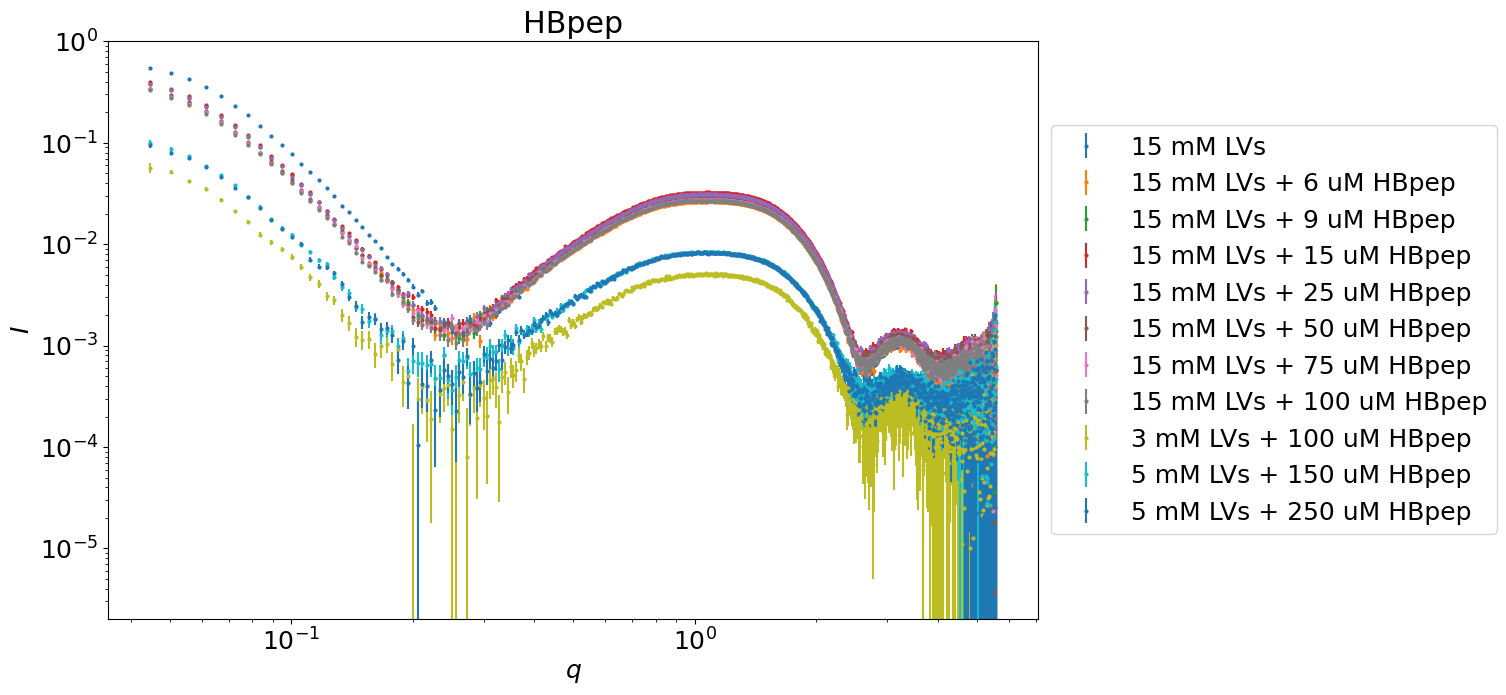

In [9]:
title = "HBpep"
lst_HBpep = [
    "BVIII_S20",
    "BVIII_S21",
    "BVIII_S22",
    "BVIII_S23",
    "BVIII_S24",
    "BVIII_S25",
    "BVIII_S26",
    "BVIII_S27",
    "BVIII_S28",
    "BVIII_S29",
]

who = lst_LV4_pure + lst_HBpep
BM29.plot_together(who, title)

In [10]:
for sample in BM29.best_fits.keys():
    if "ULV_spheric_asym_C4_lognormal" in BM29.best_fits[sample].keys():
        print(sample)

BII_S2
BII_S4
BII_S9
BII_S10
BII_S11
BIV_S1
BIV_S4
BIV_S5
BIV_S6
BIV_S7
BIV_S8
BIV_S9
BIV_S10
BIV_S11
BIV_S12
BIV_S13
BIV_S14
BIV_S15
BIV_S16
BIV_S17
BIV_S18
BIV_S19
BIV_S20
BIV_S21
BIV_S22
BIV_S23
BIV_S24
BIV_S25
BIV_S26
BIV_S27
BIV_S28
BIV_S29
BIV_S30
BIV_S31
BIV_S32
BIV_S33
BIV_S34
BIV_S35
BIV_S36
BIV_S37
BIV_S38
BIV_S39
BIV_S40
BIX_S1
BIX_S2


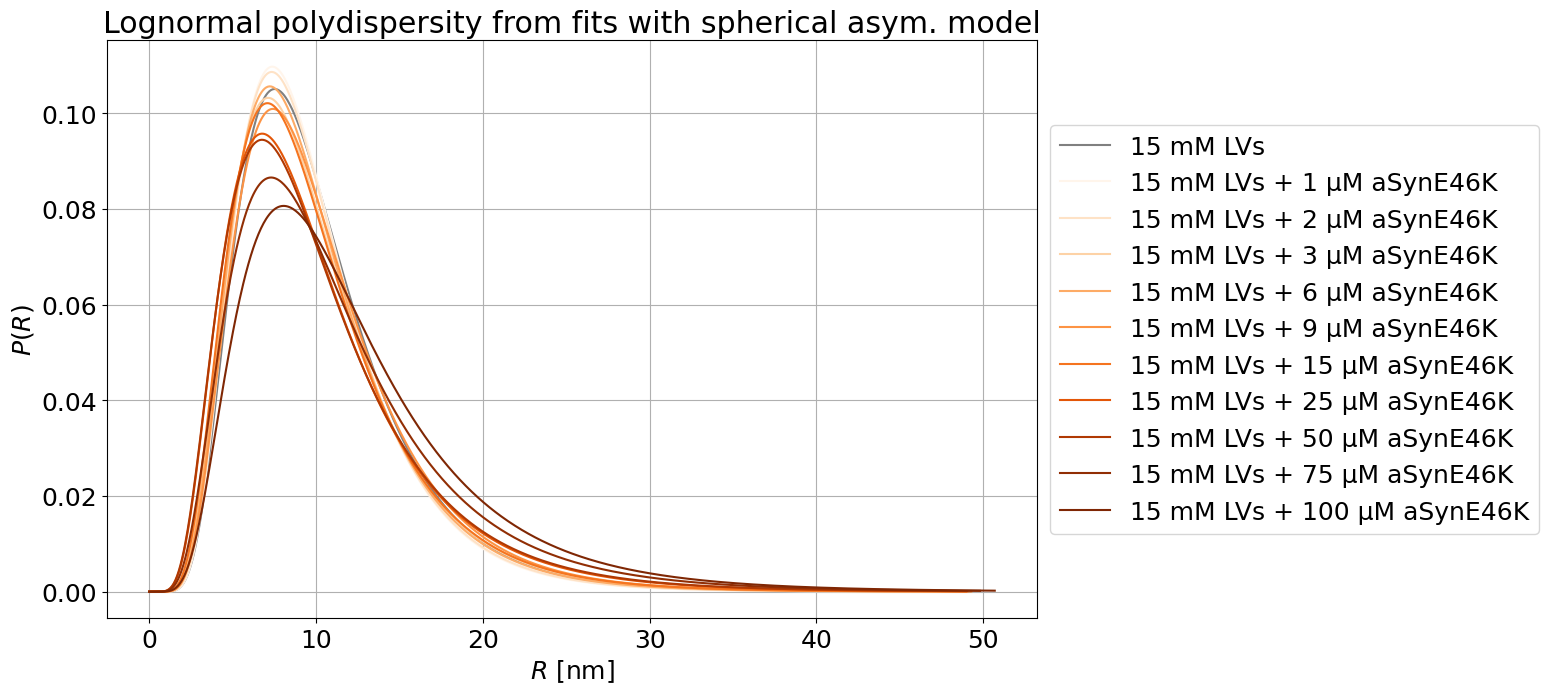

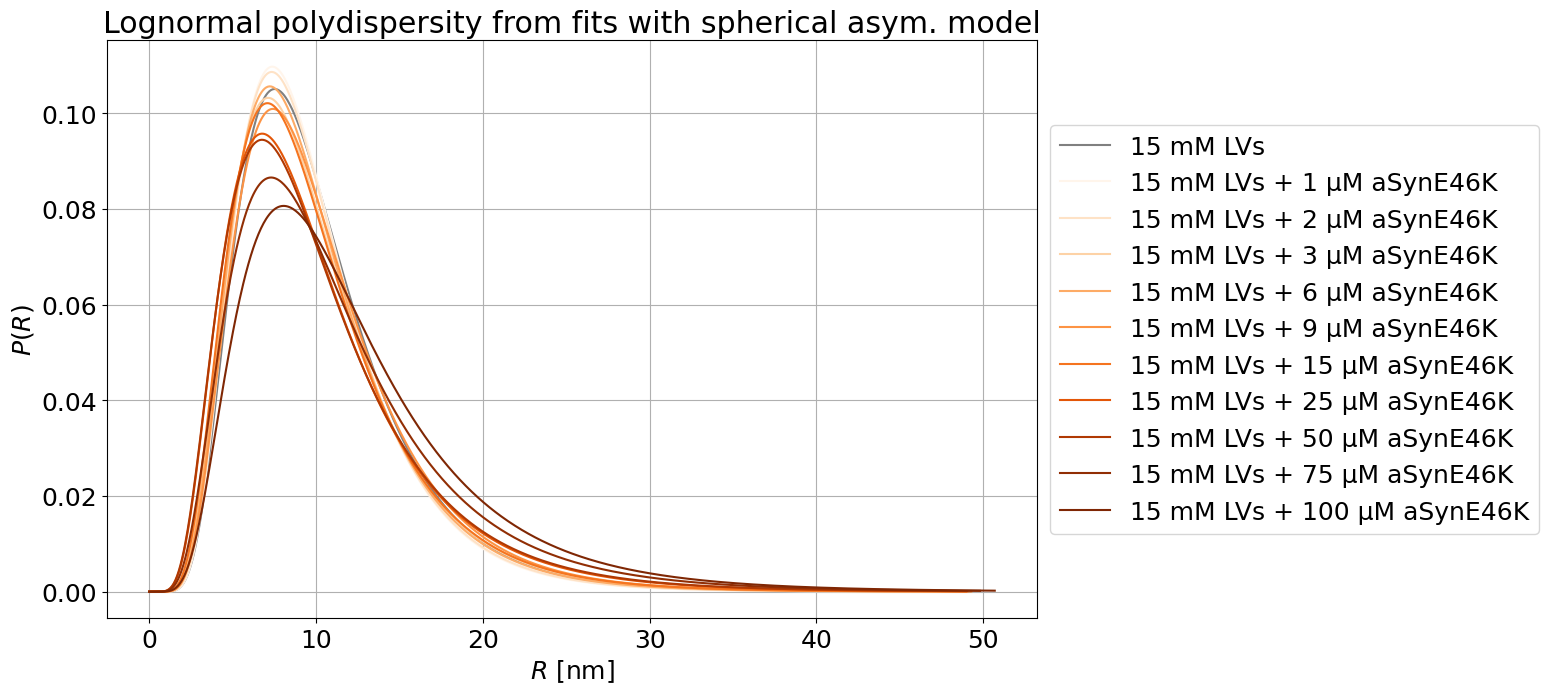

In [13]:
# PLOT LOGNORM POLYDISPERSITY FITS
who = [
    "BII_S9",
    "BIV_S31",
    "BIV_S32",
    "BIV_S33",
    "BIV_S34",
    "BIV_S35",
    "BIV_S36",
    "BIV_S37",
    "BIV_S38",
    "BIV_S39",
    "BIV_S40",
]



BM29.plot_together_lognorm_polydisp(who)